# Predicting next-day maximum temperature in Nantes

Our longer-term goal is to predict heatwaves. We will start with a **linear regression baseline** whose target is **Tmax(t+1)**: the maximum temperature on the next calendar day.


On importe les outils nécessaires pour manipuler les fichiers et les données sous forme de tableaux.

In [39]:
from pathlib import Path

import pandas as pd


## Load the daily data


On charge les données météo de Nantes, on les trie par date et on affiche un premier aperçu.

In [40]:
DATA_PATH = Path("../data/nantes_weather_daily.csv")

data = (
    pd.read_csv(DATA_PATH, parse_dates=["date"])
    .sort_values(["date"])
)

print(f"Loaded {len(data):,} data rows and {data.shape[1]} columns.")
print(f"Period: {data['date'].min()} to {data['date'].max()}")
data.head()

Loaded 997 data rows and 17 columns.
Period: 2024-01-01 00:00:00 to 2026-09-23 00:00:00


,date,lat,lon,temperature_max,temperature_min,temperature_mean,relative_humidity_mean,dew_point_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_mean,wind_speed_max,wind_dir_sin_mean,wind_dir_cos_mean,precipitation_sum,soil_moisture_mean,shortwave_radiation_sum_MJ_m2
0,2024-01-01,47.25,-1.5,12.3,7.5,9.587500,88.916667,7.845833,1011.037500,93.875000,5.290833,9.72,-0.711700,-0.661816,9.3,0.401583,3.5712
1,2024-01-02,47.25,-1.5,13.7,11.9,12.637500,91.250000,11.225000,1002.379167,82.875000,9.842917,12.38,-0.752220,-0.632226,26.4,0.432500,0.5112
2,2024-01-03,47.25,-1.5,12.8,10.8,11.995833,83.833333,9.345833,1004.583333,50.875000,8.318750,10.02,-0.913469,-0.377800,5.7,0.417208,3.4452
3,2024-01-04,47.25,-1.5,13.3,9.0,10.591667,88.708333,8.800000,1007.291667,75.916667,5.783750,9.67,-0.623036,-0.679042,5.4,0.414667,2.5416
4,2024-01-05,47.25,-1.5,10.9,4.6,7.016667,90.583333,5.504167,1006.370833,56.541667,2.275833,4.30,-0.916707,0.222461,0.0,0.404542,5.4072


## Inspect the imported data

Check column types, missing values, and duplicate timestamps per location before building daily features. These checks leave the observations unchanged.

On vérifie les types de données, les lieux présents, les valeurs manquantes et les éventuels doublons.

In [41]:
data.info()

print("\nLocations:")
display(data[["lat", "lon"]].drop_duplicates().reset_index(drop=True))

print("Missing values by column:")
display(data.isna().sum())

print("Duplicate location/time rows:", data.duplicated(["lat", "lon", "date"]).sum())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 997 entries, 0 to 996
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   date                           997 non-null    datetime64[ns]
 1   lat                            997 non-null    float64       
 2   lon                            997 non-null    float64       
 3   temperature_max                997 non-null    float64       
 4   temperature_min                997 non-null    float64       
 5   temperature_mean               997 non-null    float64       
 6   relative_humidity_mean         997 non-null    float64       
 7   dew_point_mean                 997 non-null    float64       
 8   pressure_msl_mean              997 non-null    float64       
 9   cloud_cover_mean               997 non-null    float64       
 10  wind_speed_mean                997 non-null    float64       
 11  wind_speed_max     

,lat,lon
0,47.25,-1.5


Missing values by column:


date                             0
lat                              0
lon                              0
temperature_max                  0
temperature_min                  0
temperature_mean                 0
relative_humidity_mean           0
dew_point_mean                   0
pressure_msl_mean                0
cloud_cover_mean                 0
wind_speed_mean                  0
wind_speed_max                   0
wind_dir_sin_mean                0
wind_dir_cos_mean                0
precipitation_sum                0
soil_moisture_mean               0
shortwave_radiation_sum_MJ_m2    0
dtype: int64

Duplicate location/time rows: 0


On affiche les statistiques descriptives pour examiner la répartition des valeurs de chaque variable numérique.

In [4]:
 data.describe().T

,count,mean,std,min,25%,50%,75%,max
lat,997.0,47.250000,0.000000,47.250000,47.250000,47.250000,47.250000,47.250000
lon,997.0,-1.500000,0.000000,-1.500000,-1.500000,-1.500000,-1.500000,-1.500000
temperature_max,997.0,18.513340,7.589699,-0.100000,13.000000,17.900000,23.400000,42.200000
temperature_min,997.0,9.703210,5.403008,-6.500000,6.200000,9.800000,13.500000,24.500000
temperature_mean,997.0,14.005634,6.267530,-2.041667,9.887500,13.645833,18.254167,33.175000
relative_humidity_mean,997.0,79.105441,12.751693,33.750000,73.083333,81.541667,88.708333,98.958333
dew_point_mean,997.0,9.853803,4.606375,-4.495833,7.075000,10.133333,13.158333,22.037500
pressure_msl_mean,997.0,1016.485745,8.904362,980.729167,1012.104167,1017.508333,1022.175000,1039.450000
cloud_cover_mean,997.0,62.156344,28.886629,0.000000,41.375000,69.208333,85.916667,100.000000
wind_speed_mean,997.0,3.748770,1.471694,0.662917,2.652500,3.472917,4.495000,10.000417


## Next step: prepare the linear regression baseline

1. Align each day's predictors with Tmax on the **following calendar day**, excluding rows without an observed target.
2. Split chronologically into training and test periods, then evaluate linear regression against a persistence baseline: predicted Tmax(t+1) = Tmax(t).


On associe chaque observation à la température maximale de la ligne suivante, après tri chronologique, puis on retire les lignes sans cible.

In [42]:
model_data = data.copy()

# Important : ordre chronologique garanti
model_data["date"] = pd.to_datetime(model_data["date"])
model_data = model_data.sort_values("date").reset_index(drop=True)

# Date que l'on cherche réellement à prédire
model_data["target_date"] = model_data["date"].shift(-1)

# Température correspondante
model_data["tmax_next_day"] = (
    model_data["temperature_max"].shift(-1)
)

model_data = model_data.dropna(
    subset=["target_date", "tmax_next_day"]
)

On sépare les variables météo utilisées pour la prédiction de la température maximale à prédire.

In [43]:
features = model_data.drop(
    columns=[
        "lat",
        "lon",
        "date",
        "target_date",
        "tmax_next_day",
    ]
)

target = model_data["tmax_next_day"]

On conserve les dates des observations et des températures à prédire pour les analyses suivantes.

In [44]:
feature_dates = model_data["date"]
target_dates = model_data["target_date"]

On entraîne une régression linéaire sur les premiers 60 % des données, puis on évalue ses prédictions sur la suite et on les compare à une prévision qui reprend la température du jour.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


split = int(len(model_data) * 0.6)

X_train = features.iloc[:split]
X_test = features.iloc[split:]

y_train = target.iloc[:split]
y_test = target.iloc[split:]

feature_dates_test = feature_dates.iloc[split:]
target_dates_test = target_dates.iloc[split:]

lr = LinearRegression()
lr.fit(X_train, y_train)
predictions = lr.predict(X_test)

print(f"R²: {lr.score(X_test, y_test):.3f}")
print(f"MAE: {mean_absolute_error(y_test, predictions):.5f} °C")
print(
      f"Persistence MAE: "
      f"{mean_absolute_error(y_test, X_test['temperature_max']):.5f} °C"
  )

R²: 0.908
MAE: 1.94734 °C
Persistence MAE: 1.95063 °C


On trace les températures réelles et prédites pour chaque mois complet du jeu de test, puis on enregistre les graphiques dans le dossier plots.

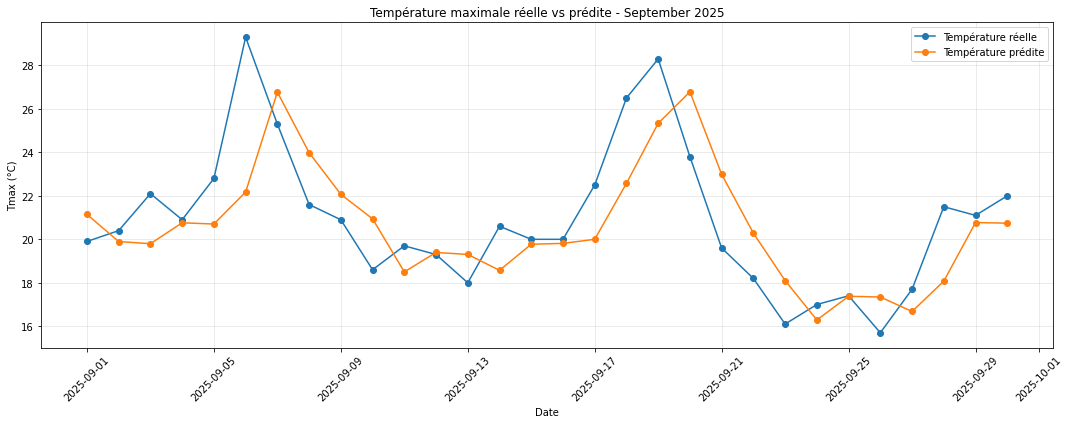

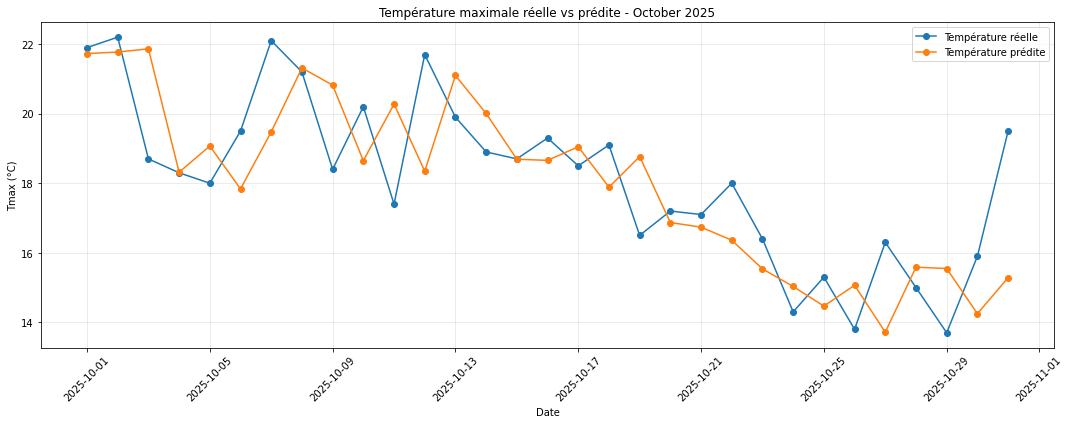

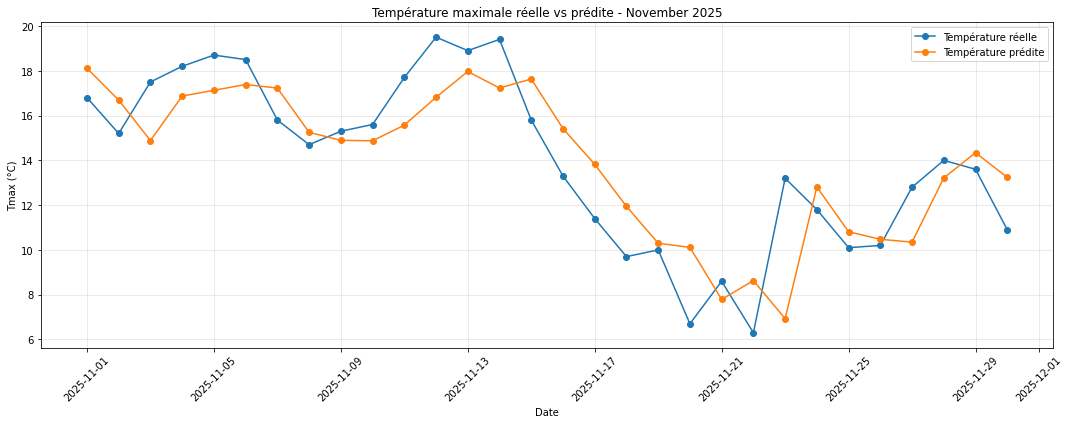

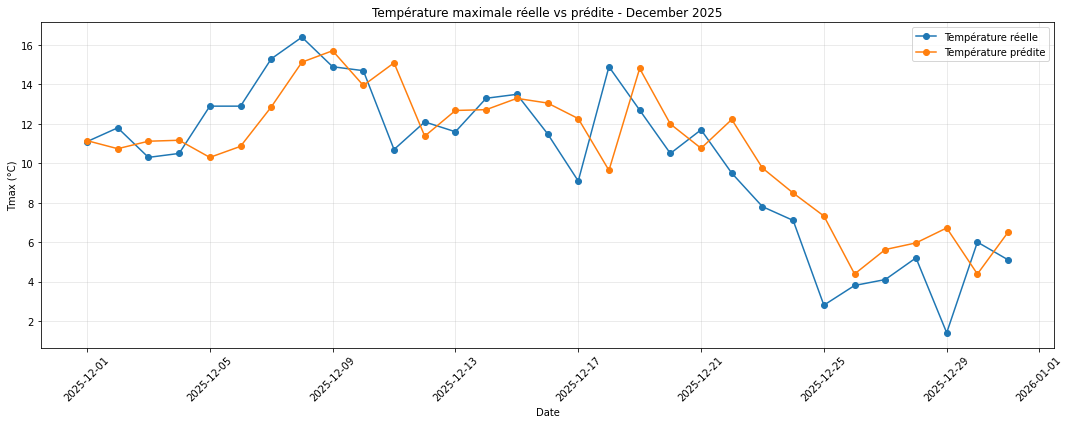

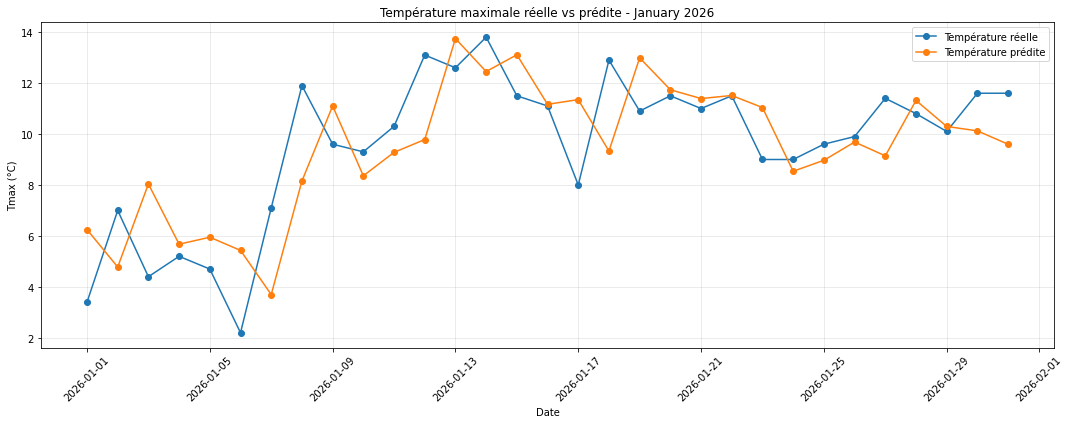

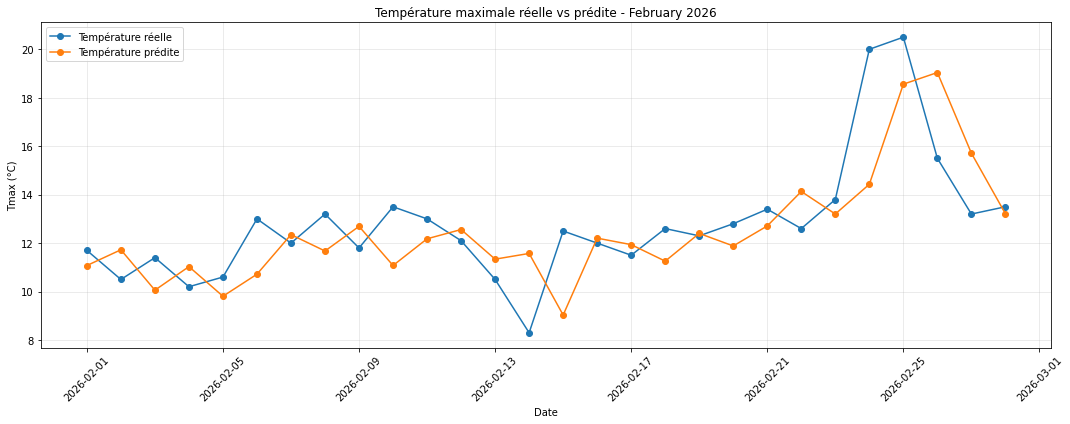

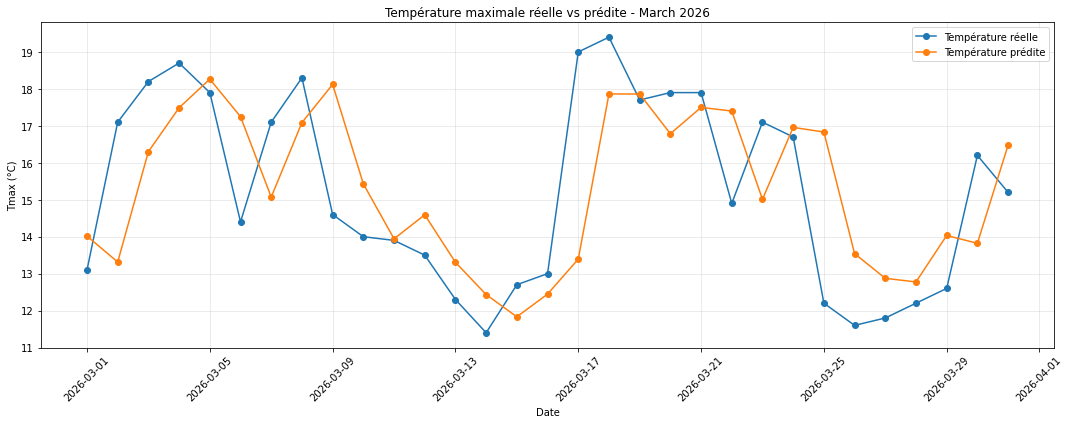

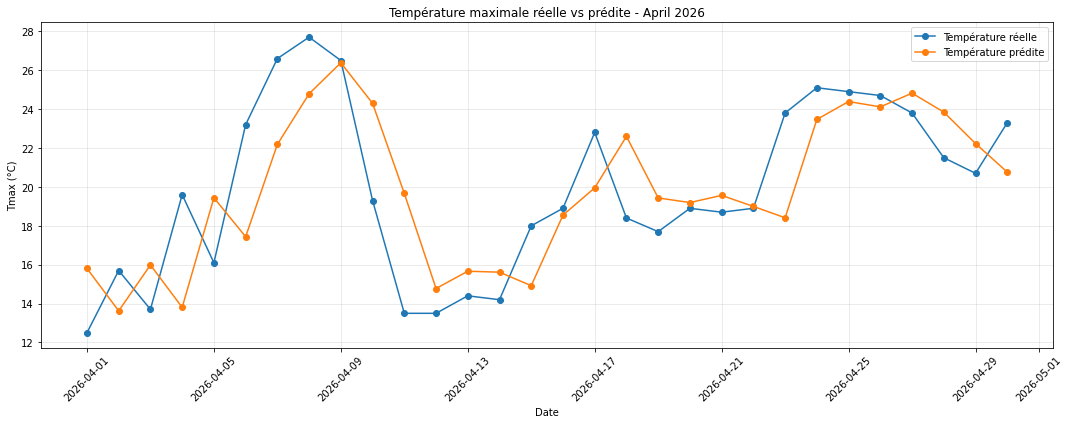

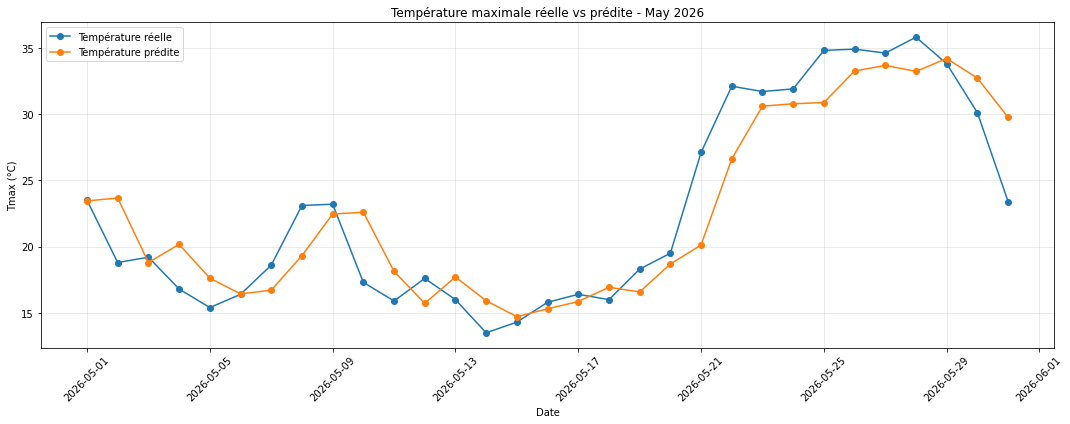

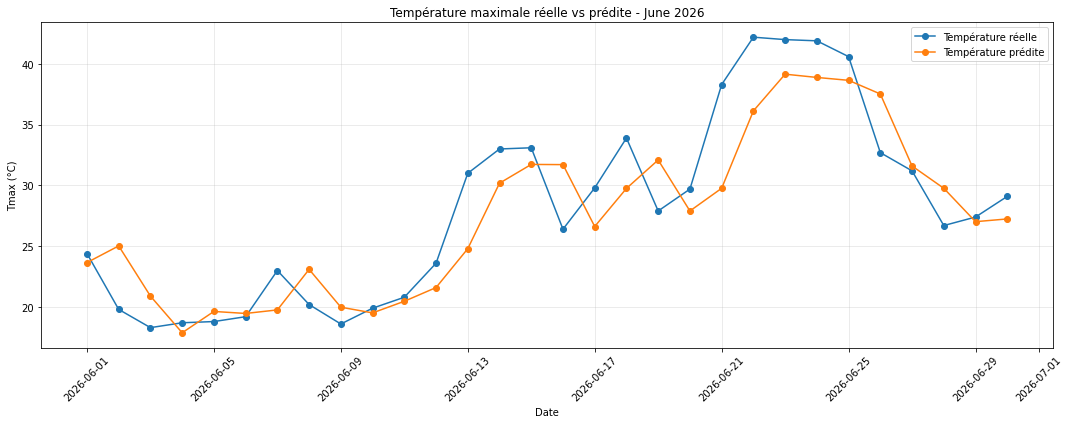

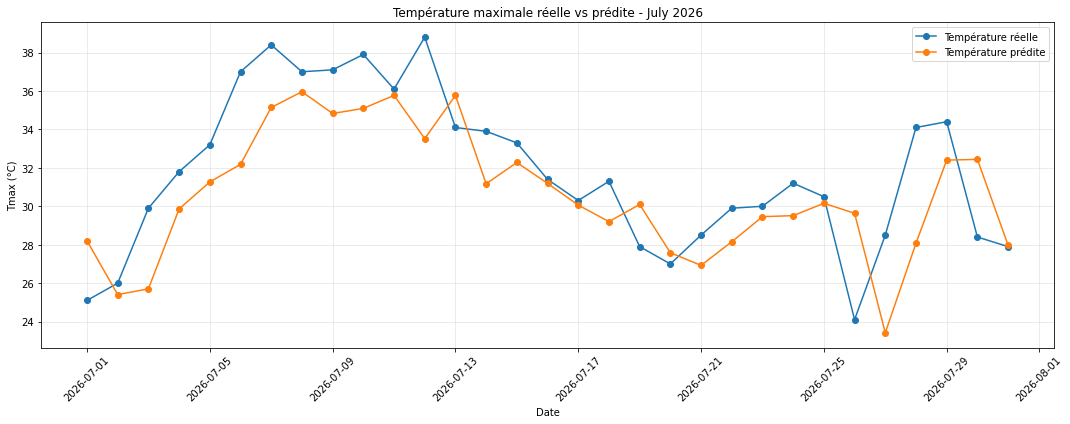

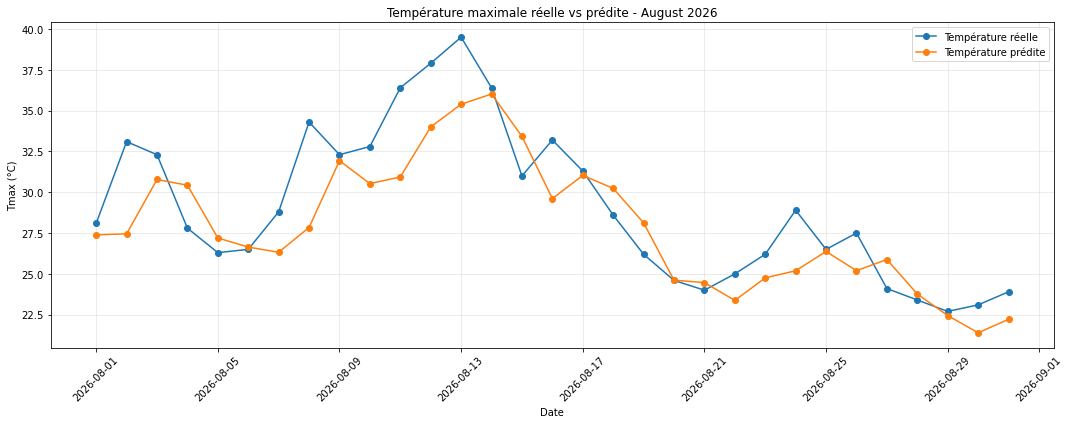

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import os


# On regroupe tout dans un DataFrame pratique
results = pd.DataFrame({
    "date": target_dates_test.values,
    "real": y_test.values,
    "pred": predictions,
    "persistence": X_test["temperature_max"].values,
})

# Colonnes utiles
results["year"] = results["date"].dt.year
results["month"] = results["date"].dt.month

os.makedirs("plots", exist_ok=True)

for (year, month), group in results.groupby(["year", "month"]):

    # Nombre de jours théorique dans ce mois
    expected_days = calendar.monthrange(year, month)[1]

    # On vérifie combien de dates différentes on a réellement
    actual_days = group["date"].dt.date.nunique()

    # Si le mois n'est pas complet, on l'ignore
    if actual_days != expected_days:
        continue

    # Tri par date, par sécurité
    group = group.sort_values("date")

    plt.figure(figsize=(15, 6))

    plt.plot(
        group["date"],
        group["real"],
        marker="o",
        label="Température réelle"
    )

    plt.plot(
        group["date"],
        group["pred"],
        marker="o",
        label="Température prédite"
    )
    
    

    plt.xlabel("Date")
    plt.ylabel("Tmax (°C)")

    month_name = calendar.month_name[month]

    plt.title(
        f"Température maximale réelle vs prédite "
        f"- {month_name} {year}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    filename = f"plots/{year}_{month:02d}.png"

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()

On affiche les coefficients de la régression, classés par valeur absolue, pour examiner le poids attribué à chaque variable.

In [ ]:
coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": lr.coef_
})

print(
    coefficients.sort_values(
        "coefficient",
        key=abs,
        ascending=False
    )
)

On rassemble les dates, la température du jour, la température réelle du lendemain et sa prédiction dans un tableau.

In [14]:
results_2 = pd.DataFrame({
    "feature_date": feature_dates_test.values,
    "target_date": target_dates_test.values,

    "tmax_previous_day":
        X_test["temperature_max"].values,

    "real":
        y_test.values,

    "pred":
        predictions,
})

On calcule les variations de température réelles et prédites, ainsi que les erreurs de prédiction.

In [16]:
results_2["real_change"] = (
    results_2["real"]
    - results_2["tmax_previous_day"]
)

results_2["predicted_change"] = (
    results_2["pred"]
    - results_2["tmax_previous_day"]
)

results_2["error"] = (
    results_2["real"]
    - results_2["pred"]
)

results_2["absolute_error"] = (
    results_2["error"].abs()
)

On visualise les erreurs de prédiction en fonction de l’amplitude du changement de température entre deux jours.

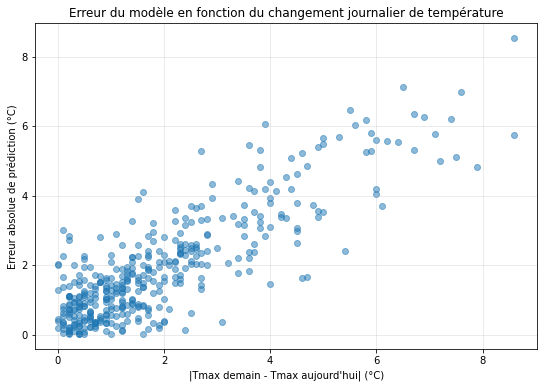

In [18]:
plt.figure(figsize=(9, 6))

plt.scatter(
    results_2["real_change"].abs(),
    results_2["absolute_error"],
    alpha=0.5
)

plt.xlabel(
    "|Tmax demain - Tmax aujourd'hui| (°C)"
)

plt.ylabel(
    "Erreur absolue de prédiction (°C)"
)

plt.title(
    "Erreur du modèle en fonction "
    "du changement journalier de température"
)

plt.grid(alpha=0.3)
plt.show()

On compare les changements de température prédits aux changements réels pour voir si le modèle les anticipe correctement.

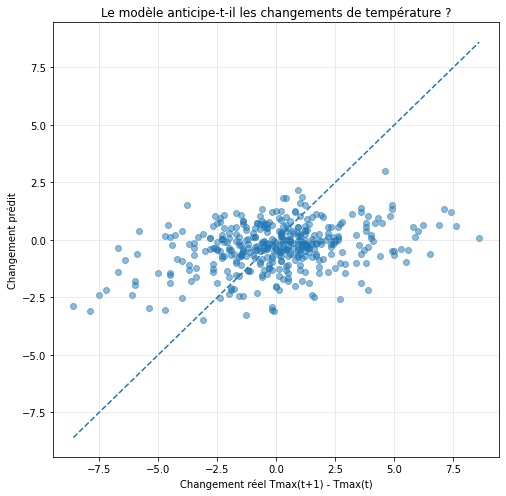

In [20]:
plt.figure(figsize=(8, 8))

plt.scatter(
    results_2["real_change"],
    results_2["predicted_change"],
    alpha=0.5
)

minimum = min(
    results_2["real_change"].min(),
    results_2["predicted_change"].min()
)

maximum = max(
    results_2["real_change"].max(),
    results_2["predicted_change"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Changement réel Tmax(t+1) - Tmax(t)"
)

plt.ylabel(
    "Changement prédit"
)

plt.title(
    "Le modèle anticipe-t-il les changements de température ?"
)

plt.grid(alpha=0.3)
plt.show()

On regroupe les changements de température par amplitude et on calcule l’erreur absolue moyenne dans chaque groupe.

In [23]:
results_2["absolute_change"] = (
    results_2["real_change"].abs()
)

results_2["change_category"] = pd.cut(
    results_2["absolute_change"],
    bins=[0, 1, 2, 4, 6, float("inf")],
    labels=[
        "0-1°C",
        "1-2°C",
        "2-4°C",
        "4-6°C",
        ">6°C"
    ],
    include_lowest=True
)

print(
    results_2.groupby("change_category")[
        "absolute_error"
    ].mean()
)

change_category
0-1°C    0.887594
1-2°C    1.451246
2-4°C    2.753978
4-6°C    4.290140
>6°C     5.869386
Name: absolute_error, dtype: float64


On ajoute les températures des deux observations précédentes et les variations récentes de température, de pression et d’humidité, puis on retire les lignes incomplètes.

In [28]:
df = model_data.copy()

df["tmax_lag1"] = df["temperature_max"].shift(1)
df["tmax_lag2"] = df["temperature_max"].shift(2)

df["delta_tmax"] = (
    df["temperature_max"]
    - df["temperature_max"].shift(1)
)

df["delta_pressure"] = (
    df["pressure_msl_mean"]
    - df["pressure_msl_mean"].shift(1)
)

df["delta_humidity"] = (
    df["relative_humidity_mean"]
    - df["relative_humidity_mean"].shift(1)
)

df = df.dropna(subset=["tmax_lag1", "tmax_lag2", "delta_tmax", "delta_pressure", "delta_humidity"])

On prépare les variables explicatives enrichies et la température maximale à prédire pour le nouveau modèle.

In [29]:
features_2 = df.drop(
    columns=[
        "lat",
        "lon",
        "date",
        "target_date",
        "tmax_next_day",
    ]
)

target_2 = df["tmax_next_day"]

On conserve les dates associées aux données enrichies pour pouvoir situer les prédictions dans le temps.

In [30]:
feature_dates_2 = df["date"]
target_dates_2 = df["target_date"]

On entraîne et on évalue une nouvelle régression linéaire avec les variables ajoutées, en gardant une séparation chronologique de 60 % pour l’entraînement.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


split = int(len(df) * 0.6)

X_train = features_2.iloc[:split]
X_test = features_2.iloc[split:]

y_train = target_2.iloc[:split]
y_test = target_2.iloc[split:]

feature_dates_test = feature_dates_2.iloc[split:]
target_dates_test = target_dates_2.iloc[split:]

lr = LinearRegression()
lr.fit(X_train, y_train)
predictions = lr.predict(X_test)

print(f"R²: {lr.score(X_test, y_test):.3f}")
print(f"MAE: {mean_absolute_error(y_test, predictions):.5f} °C")
print(
      f"Persistence MAE: "
      f"{mean_absolute_error(y_test, X_test['temperature_max']):.5f} °C"
  )

R²: 0.912
MAE: 1.91187 °C
Persistence MAE: 1.95251 °C


On examine les coefficients de cette nouvelle régression pour voir le poids attribué aux variables ajoutées.

In [32]:
coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": lr.coef_
})

print(
    coefficients.sort_values(
        "coefficient",
        key=abs,
        ascending=False
    )
)

                          feature  coefficient
12             soil_moisture_mean    -8.108994
2                temperature_mean     0.529067
8                  wind_speed_max    -0.398580
7                 wind_speed_mean     0.362878
9               wind_dir_sin_mean     0.314109
0                 temperature_max     0.298766
10              wind_dir_cos_mean    -0.296727
16                     delta_tmax     0.225078
1                 temperature_min    -0.158540
15                      tmax_lag2     0.112384
17                 delta_pressure     0.093195
13  shortwave_radiation_sum_MJ_m2     0.089551
11              precipitation_sum     0.076835
14                      tmax_lag1     0.073688
3          relative_humidity_mean     0.028632
5               pressure_msl_mean     0.017632
18                 delta_humidity    -0.005763
4                  dew_point_mean     0.003274
6                cloud_cover_mean     0.002174


On trace les températures réelles et prédites par la régression enrichie pour chaque mois complet et on enregistre les graphiques dans plots.

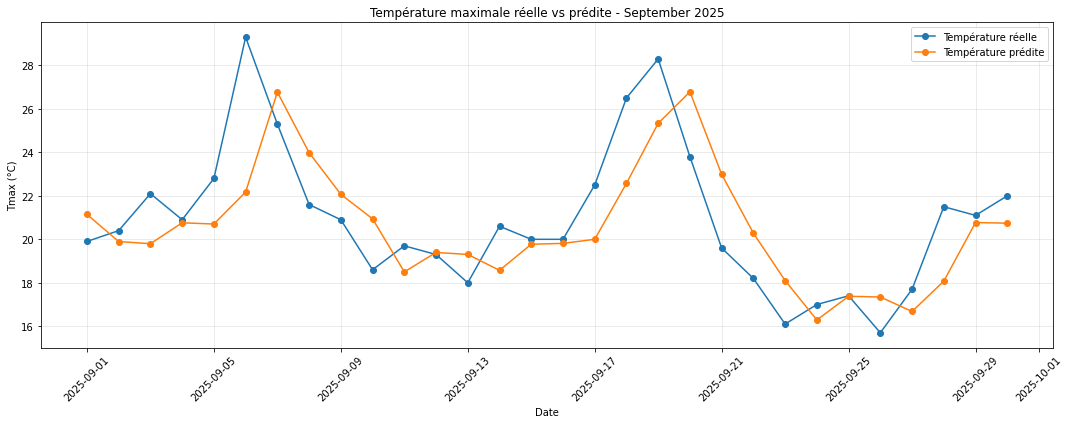

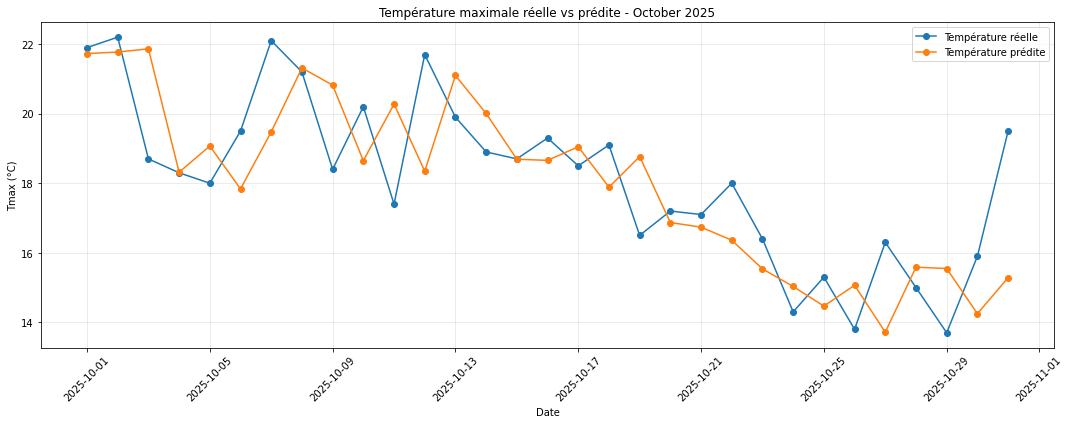

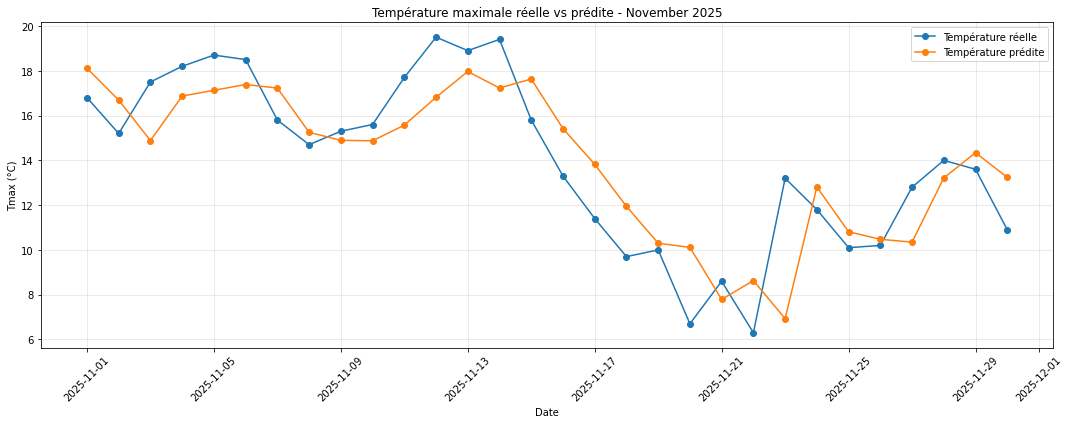

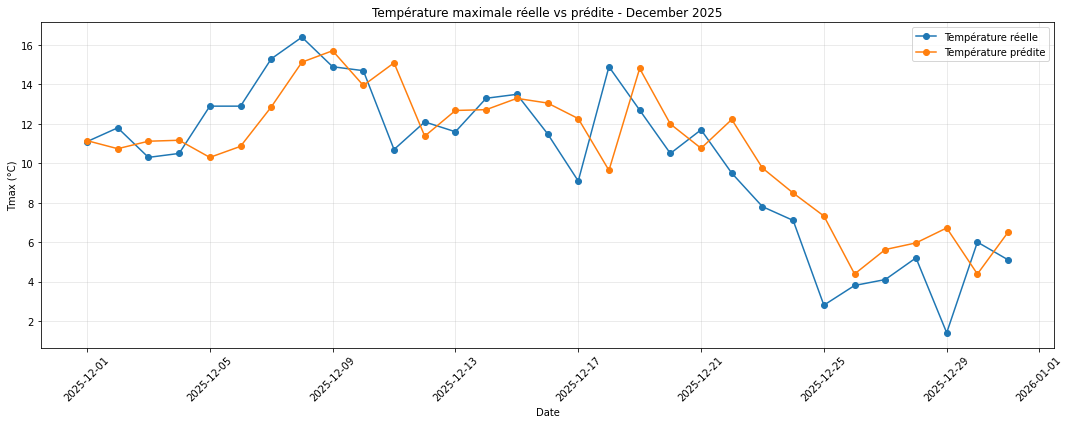

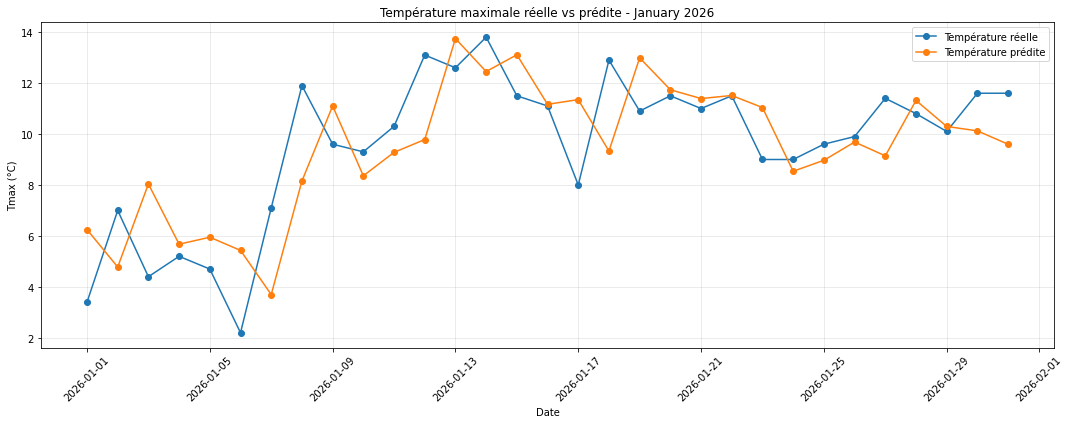

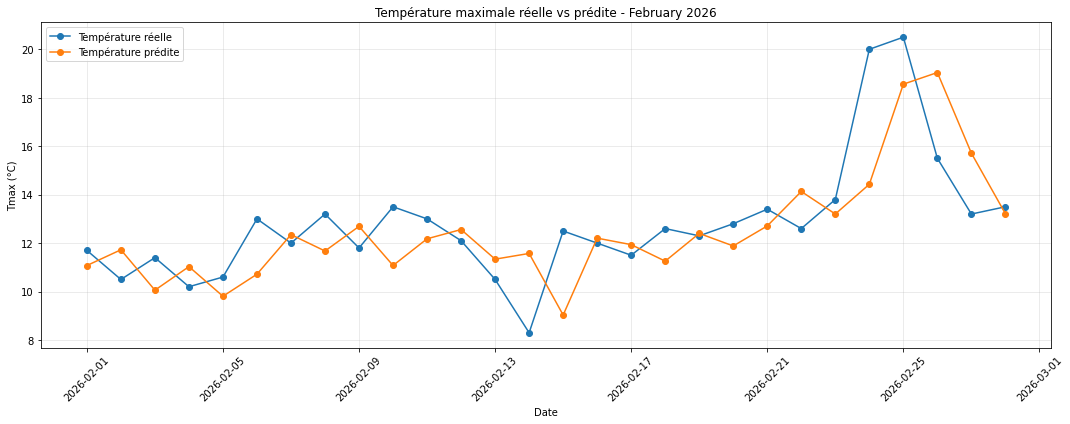

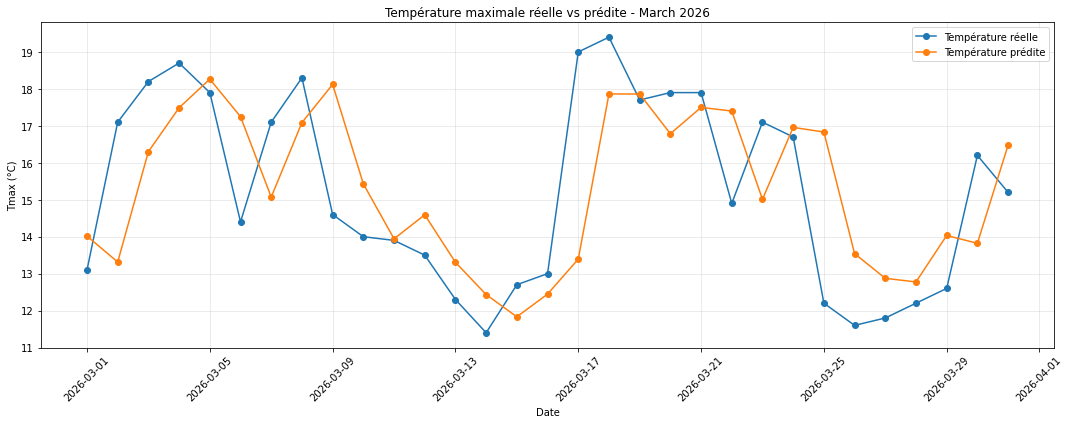

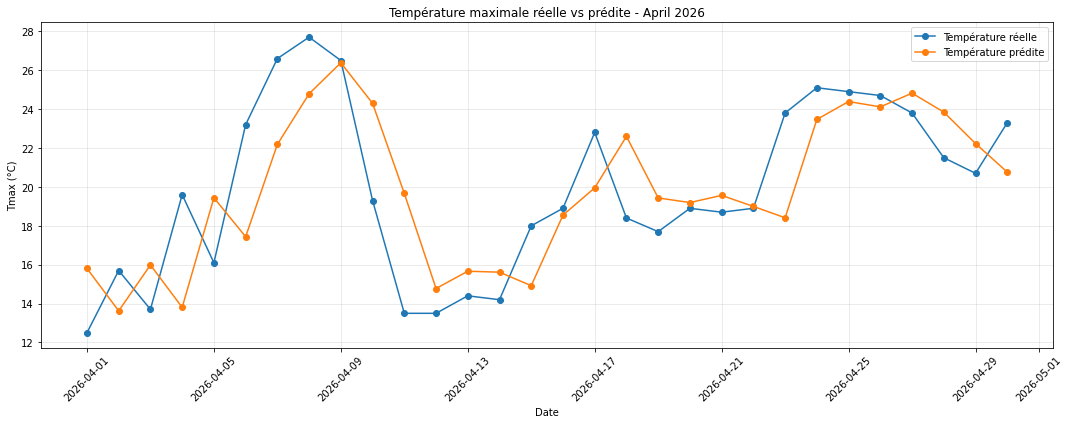

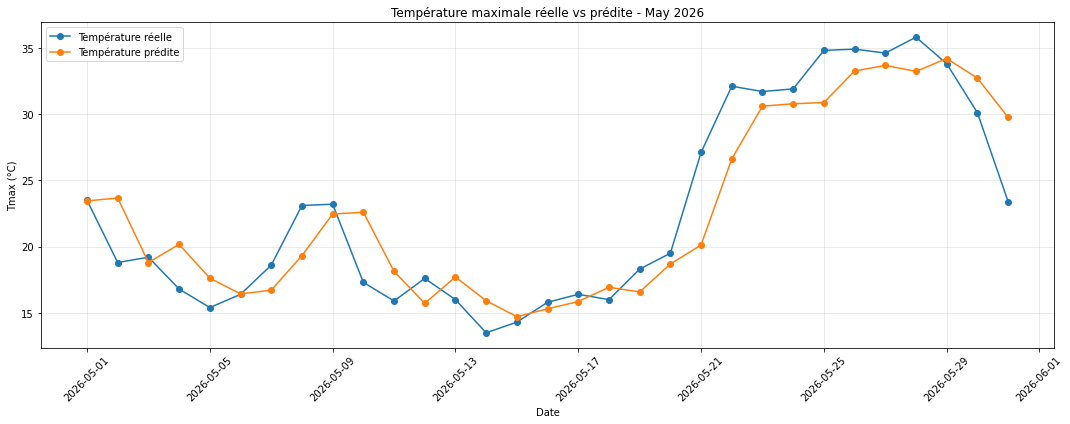

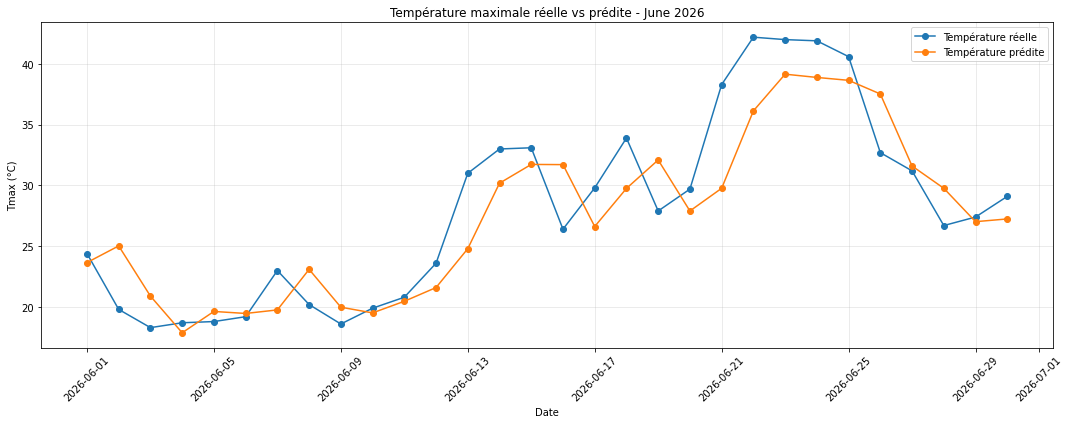

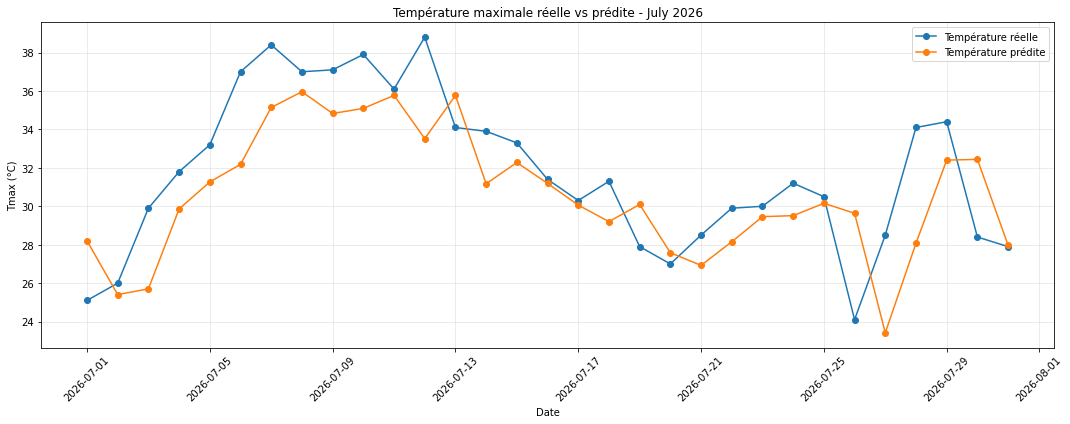

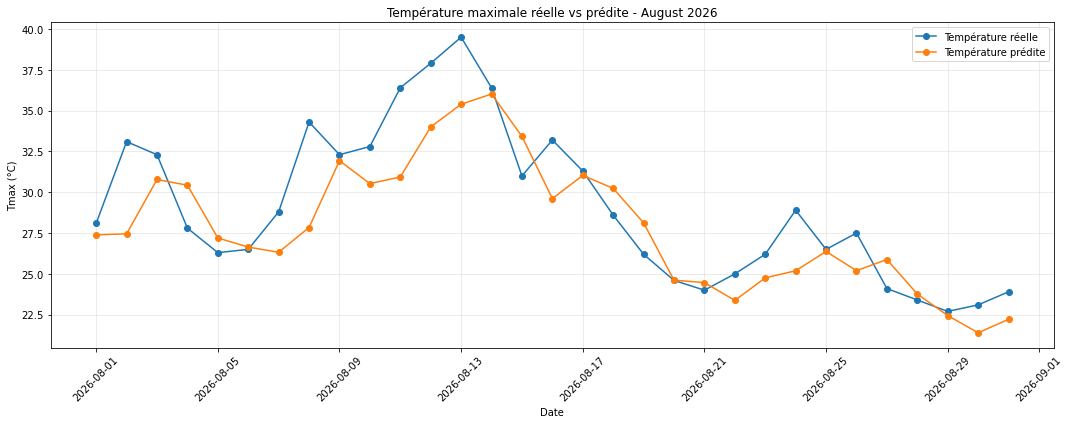

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import os


# On regroupe tout dans un DataFrame pratique
results = pd.DataFrame({
    "date": target_dates_test.values,
    "real": y_test.values,
    "pred": predictions,
    "persistence": X_test["temperature_max"].values,
})

# Colonnes utiles
results["year"] = results["date"].dt.year
results["month"] = results["date"].dt.month

os.makedirs("plots", exist_ok=True)

for (year, month), group in results.groupby(["year", "month"]):

    # Nombre de jours théorique dans ce mois
    expected_days = calendar.monthrange(year, month)[1]

    # On vérifie combien de dates différentes on a réellement
    actual_days = group["date"].dt.date.nunique()

    # Si le mois n'est pas complet, on l'ignore
    if actual_days != expected_days:
        continue

    # Tri par date, par sécurité
    group = group.sort_values("date")

    plt.figure(figsize=(15, 6))

    plt.plot(
        group["date"],
        group["real"],
        marker="o",
        label="Température réelle"
    )

    plt.plot(
        group["date"],
        group["pred"],
        marker="o",
        label="Température prédite"
    )
    
    

    plt.xlabel("Date")
    plt.ylabel("Tmax (°C)")

    month_name = calendar.month_name[month]

    plt.title(
        f"Température maximale réelle vs prédite "
        f"- {month_name} {year}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    filename = f"plots/{year}_{month:02d}.png"

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()

On entraîne une forêt aléatoire de 500 arbres sur les données enrichies et on évalue la qualité de ses prédictions.

In [46]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

predictions_rf = rf.predict(X_test)

r2_rf = rf.score(X_test, y_test)

mae_rf = mean_absolute_error(
    y_test,
    predictions_rf
)

print(f"R²: {r2_rf:.3f}")
print(f"MAE Random Forest: {mae_rf:.5f} °C")
print(f"Persistence MAE: {mae_persistence:.5f} °C")

R²: 0.885
MAE Random Forest: 2.09744 °C


NameError: name 'mae_persistence' is not defined

On compare les températures réelles aux prédictions de la forêt aléatoire pour chaque mois complet et on enregistre les graphiques dans plots_rf.

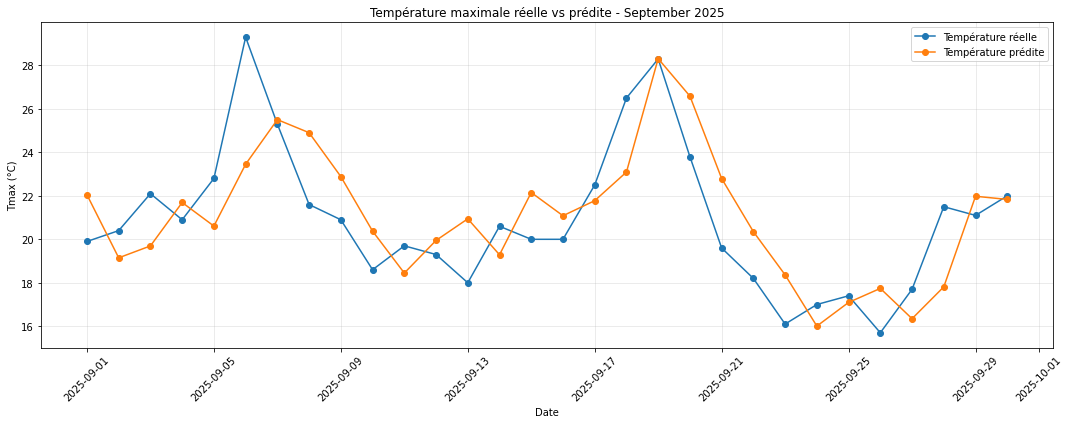

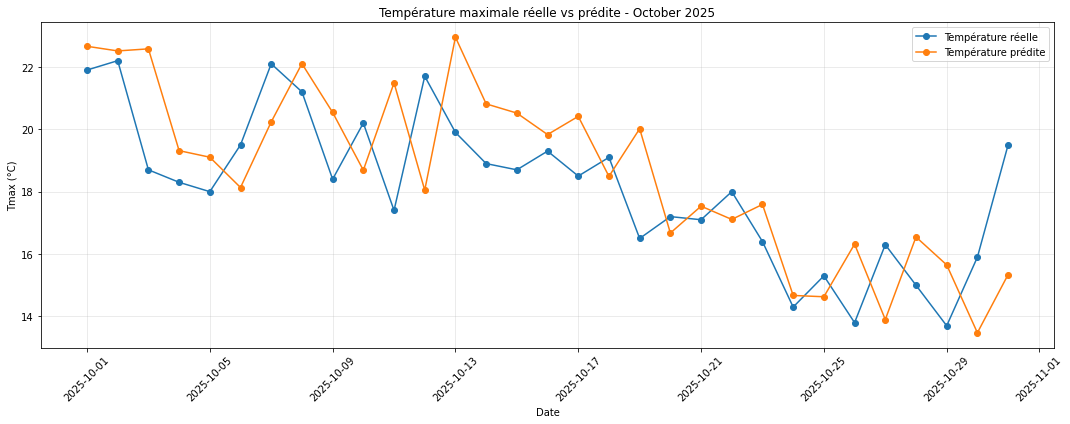

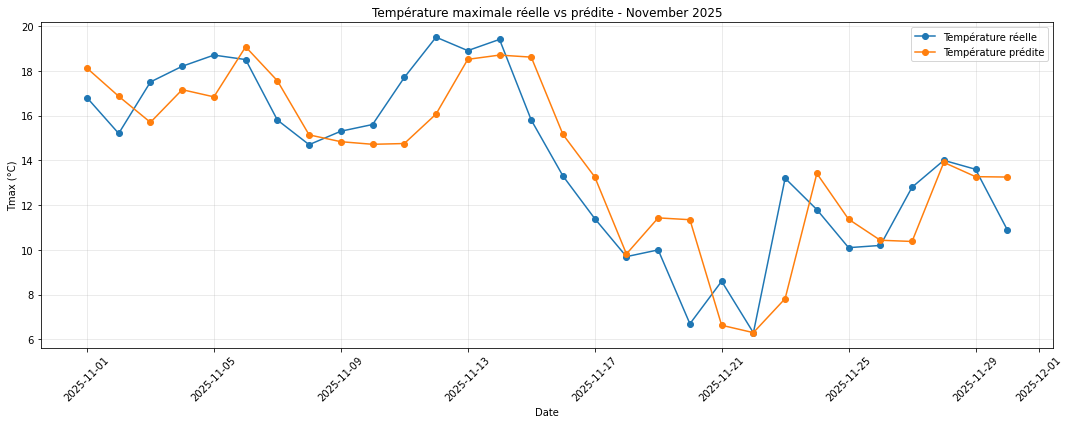

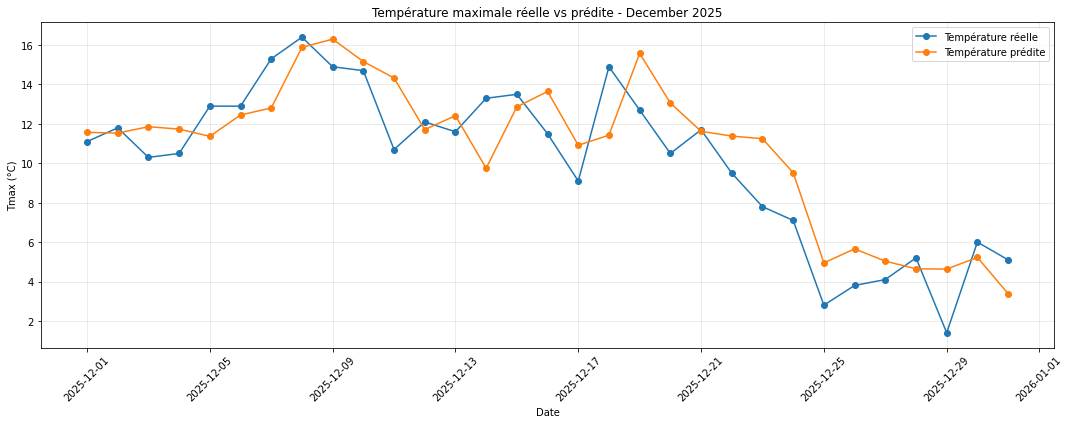

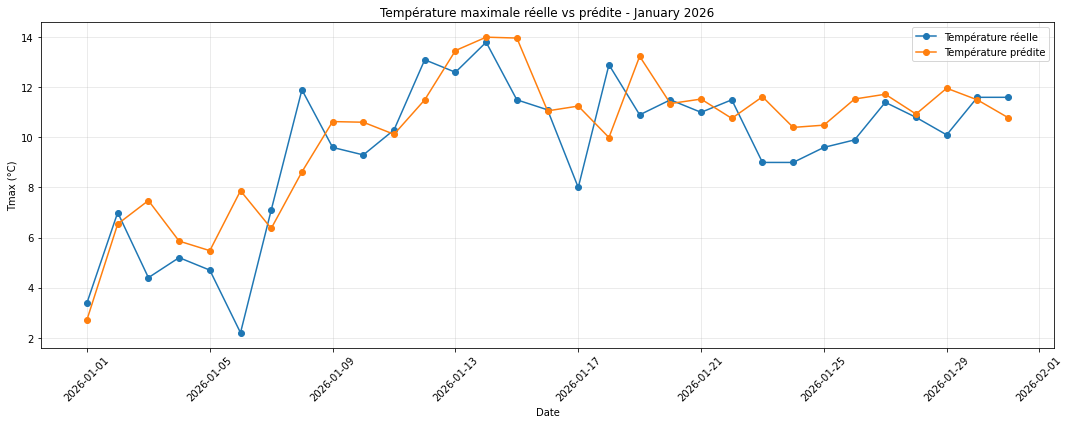

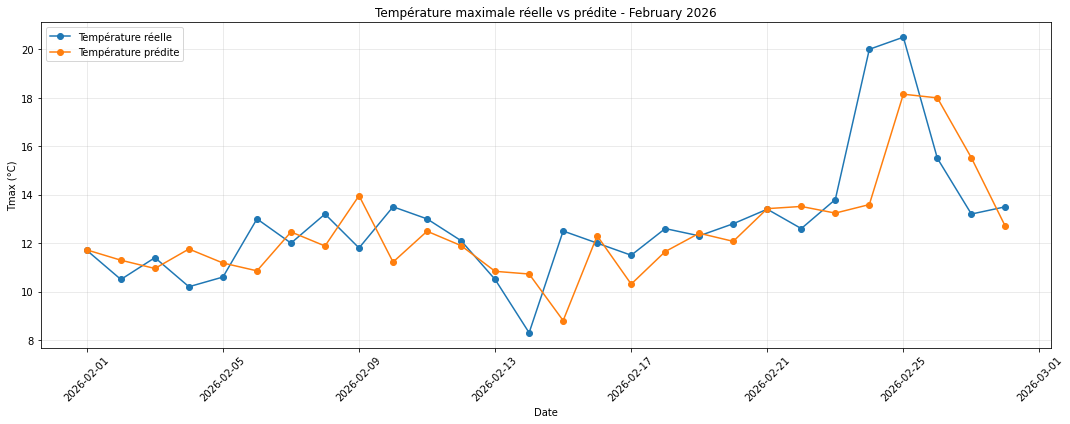

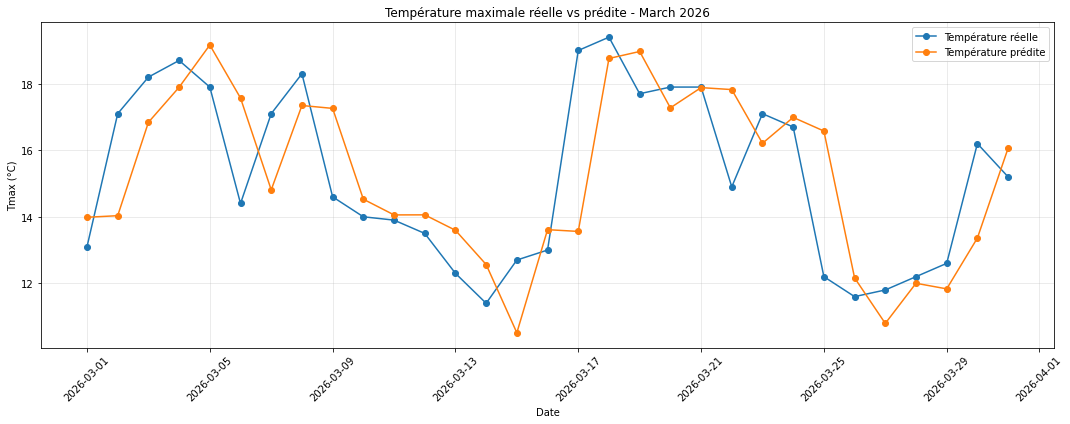

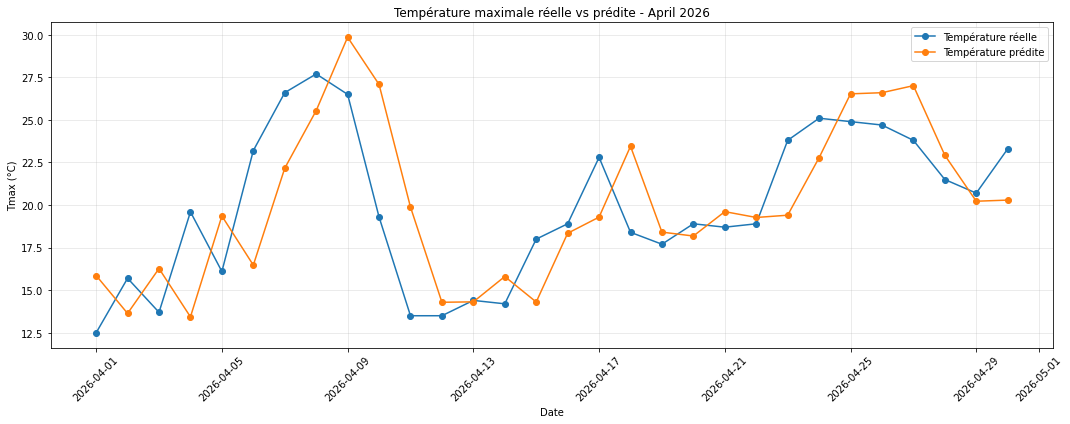

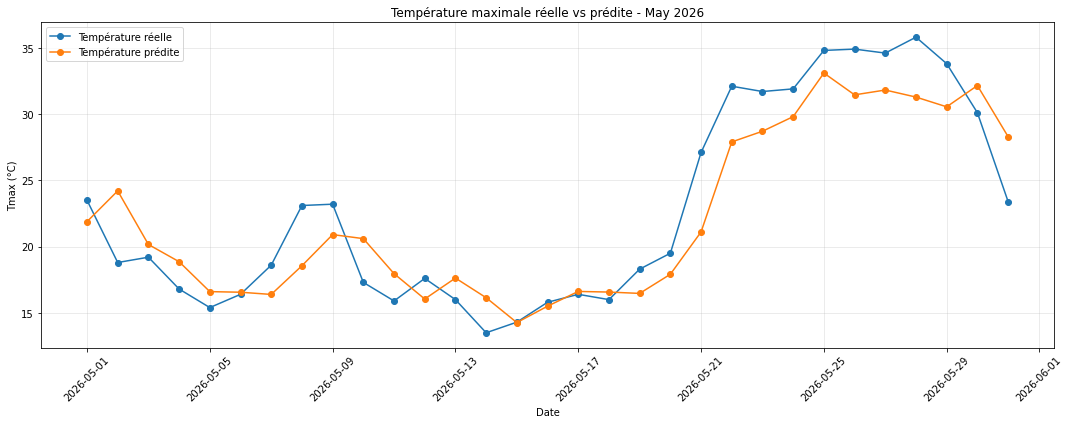

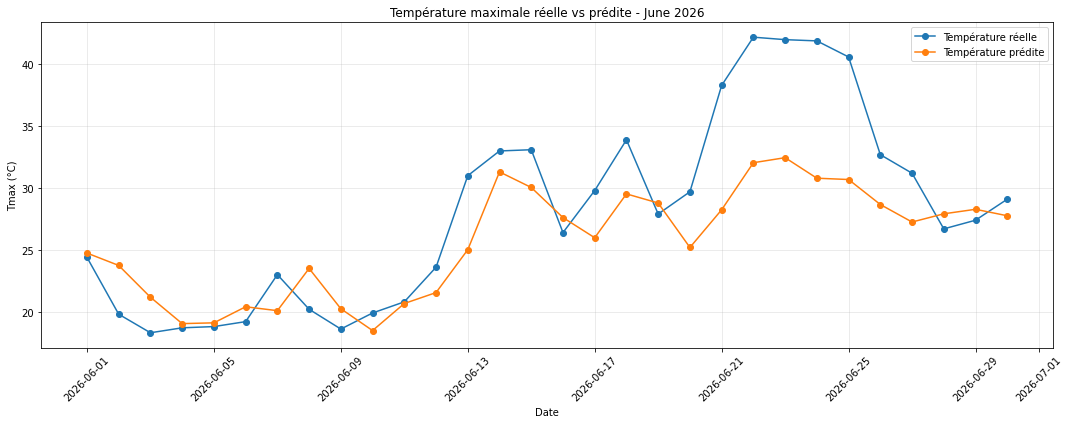

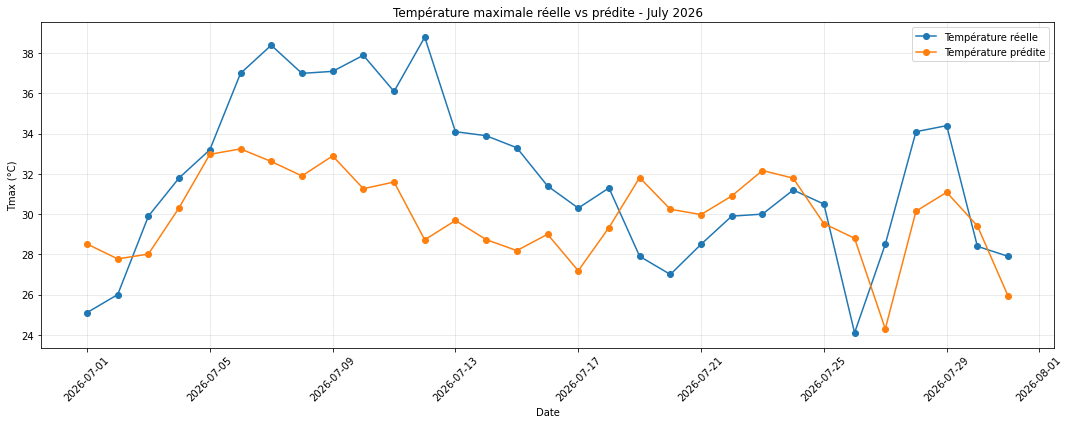

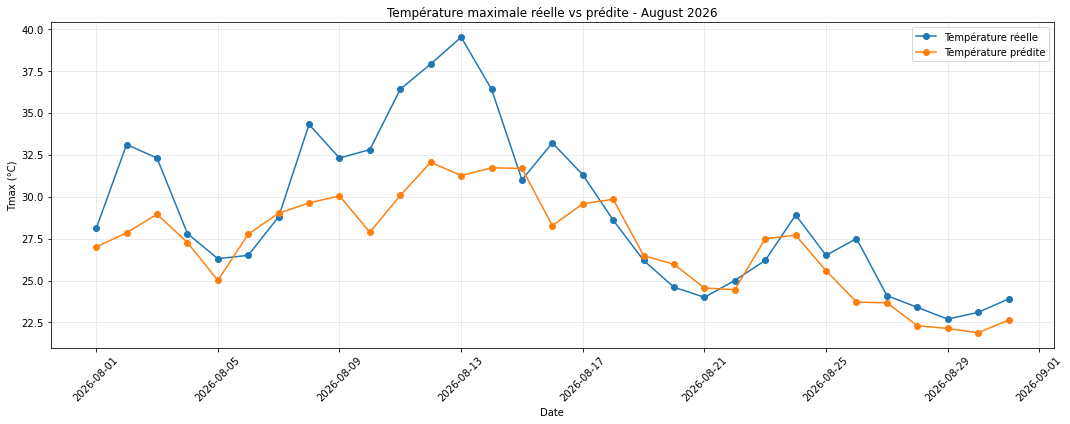

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import os


# On regroupe tout dans un DataFrame pratique
results = pd.DataFrame({
    "date": target_dates_test.values,
    "real": y_test.values,
    "pred": predictions_rf,
    "persistence": X_test["temperature_max"].values,
})

# Colonnes utiles
results["year"] = results["date"].dt.year
results["month"] = results["date"].dt.month

os.makedirs("plots_rf", exist_ok=True)

for (year, month), group in results.groupby(["year", "month"]):

    # Nombre de jours théorique dans ce mois
    expected_days = calendar.monthrange(year, month)[1]

    # On vérifie combien de dates différentes on a réellement
    actual_days = group["date"].dt.date.nunique()

    # Si le mois n'est pas complet, on l'ignore
    if actual_days != expected_days:
        continue

    # Tri par date, par sécurité
    group = group.sort_values("date")

    plt.figure(figsize=(15, 6))

    plt.plot(
        group["date"],
        group["real"],
        marker="o",
        label="Température réelle"
    )

    plt.plot(
        group["date"],
        group["pred"],
        marker="o",
        label="Température prédite"
    )
    
    

    plt.xlabel("Date")
    plt.ylabel("Tmax (°C)")

    month_name = calendar.month_name[month]

    plt.title(
        f"Température maximale réelle vs prédite "
        f"- {month_name} {year}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    filename = f"plots_rf/{year}_{month:02d}.png"

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()

On entraîne un modèle de gradient boosting sur les mêmes données et on compare son erreur à celle d’une prévision qui reprend la température du jour.

In [53]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

hgb = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

hgb.fit(X_train, y_train)

predictions_hgb = hgb.predict(X_test)

# Métriques
r2_hgb = hgb.score(X_test, y_test)

mae_hgb = mean_absolute_error(
    y_test,
    predictions_hgb
)

mae_persistence = mean_absolute_error(
    y_test,
    X_test["temperature_max"]
)

print(f"R²: {r2_hgb:.3f}")
print(f"MAE HGB: {mae_hgb:.5f} °C")
print(f"Persistence MAE: {mae_persistence:.5f} °C")

R²: 0.873
MAE HGB: 2.23132 °C
Persistence MAE: 1.95063 °C


On compare les températures réelles aux prédictions du gradient boosting pour chaque mois complet et on enregistre les graphiques dans plots_hgb.

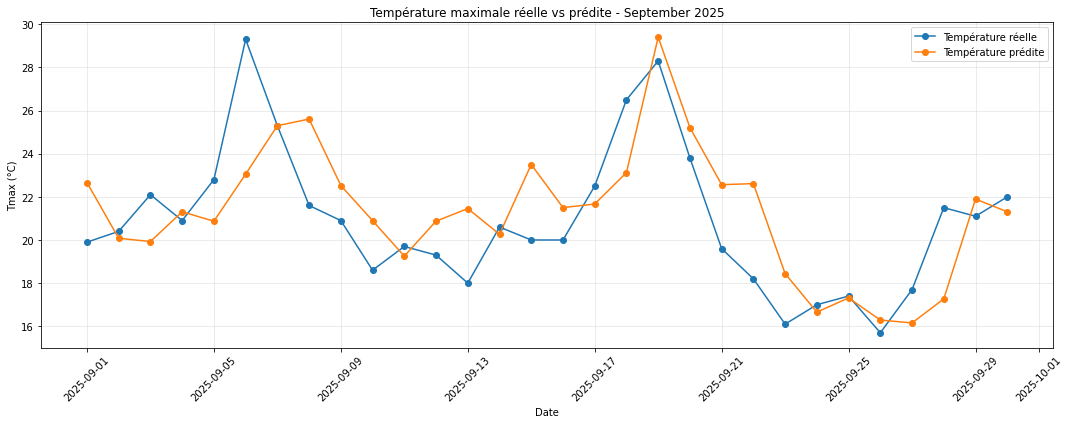

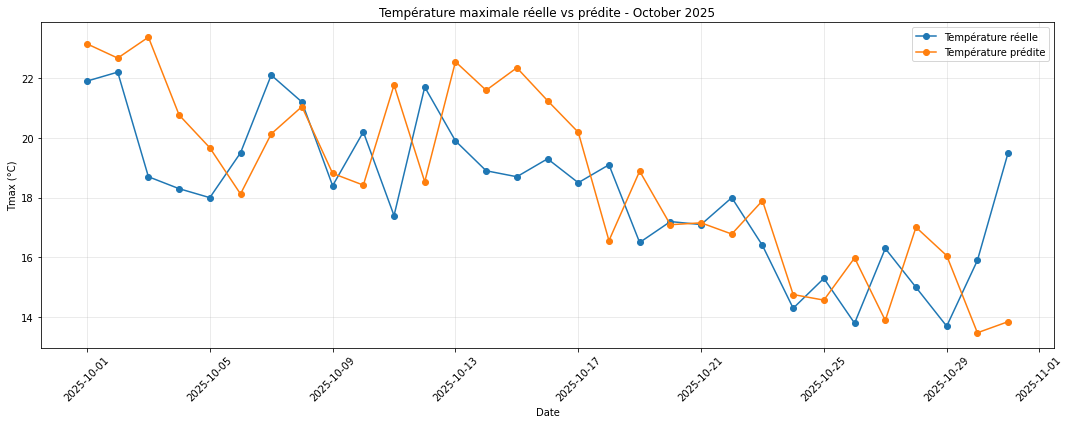

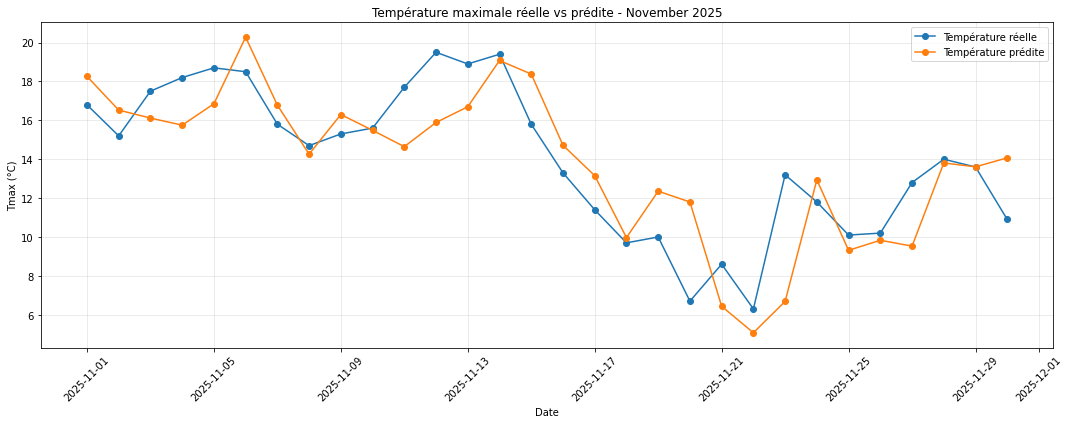

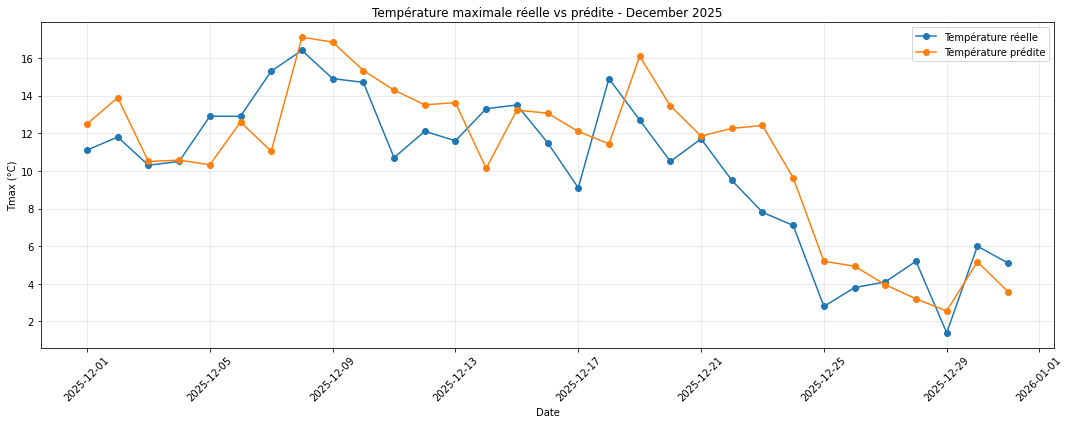

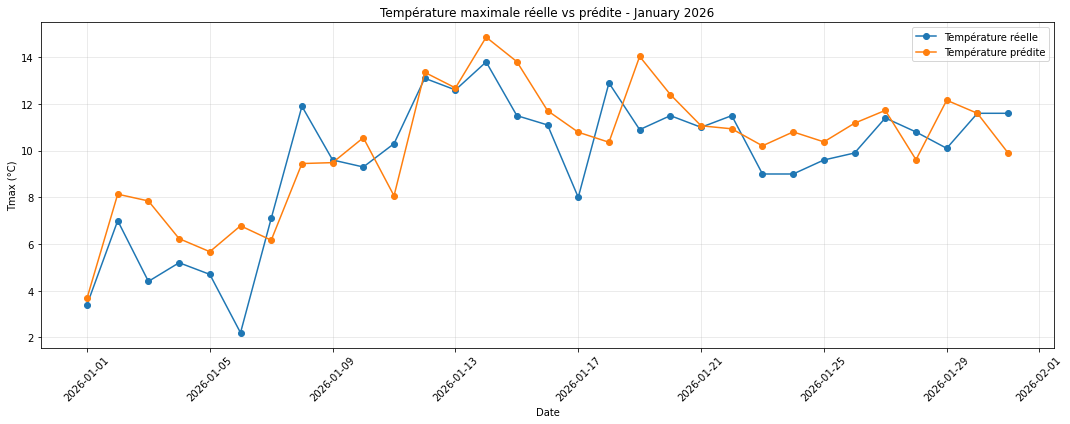

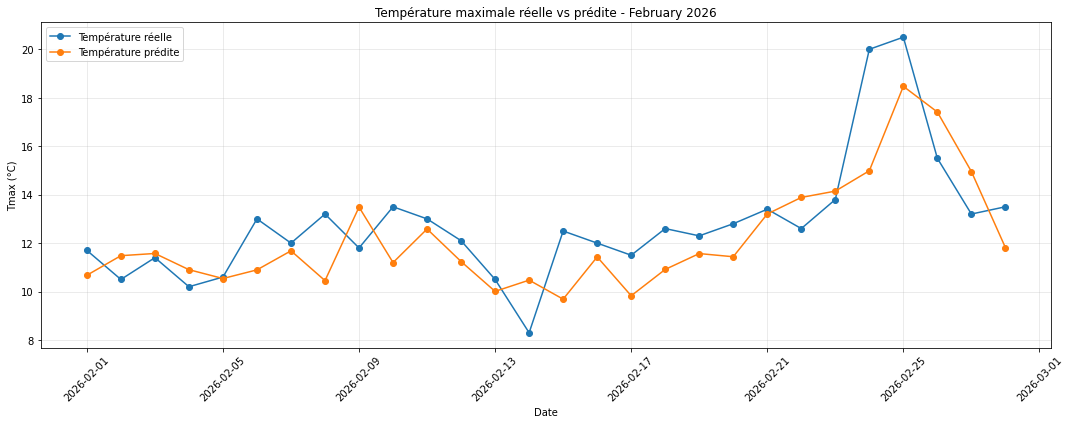

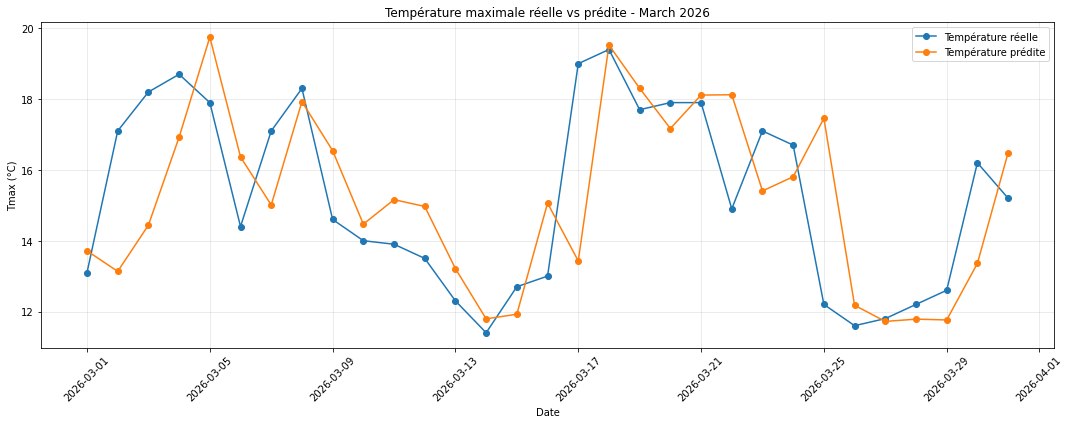

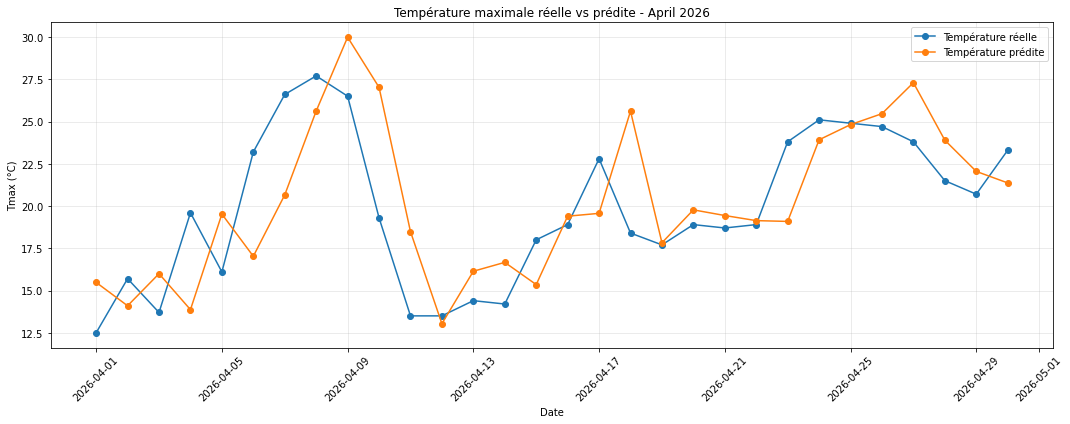

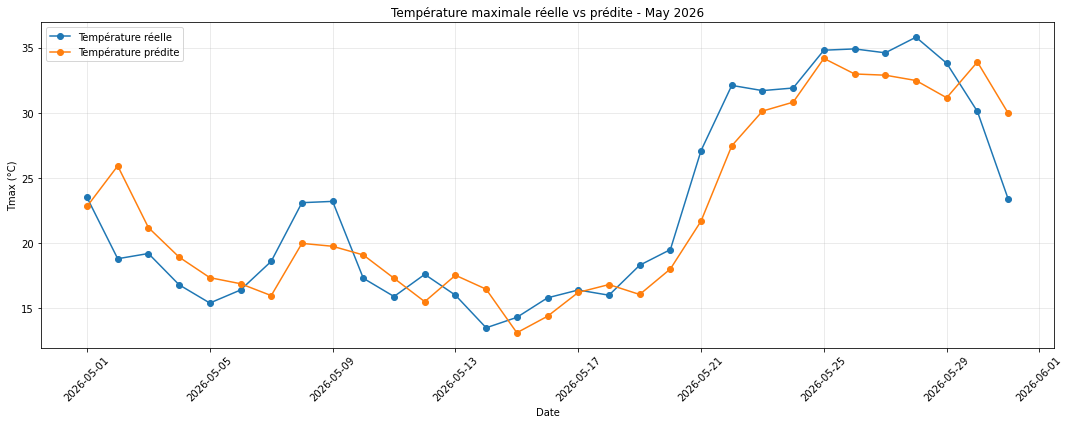

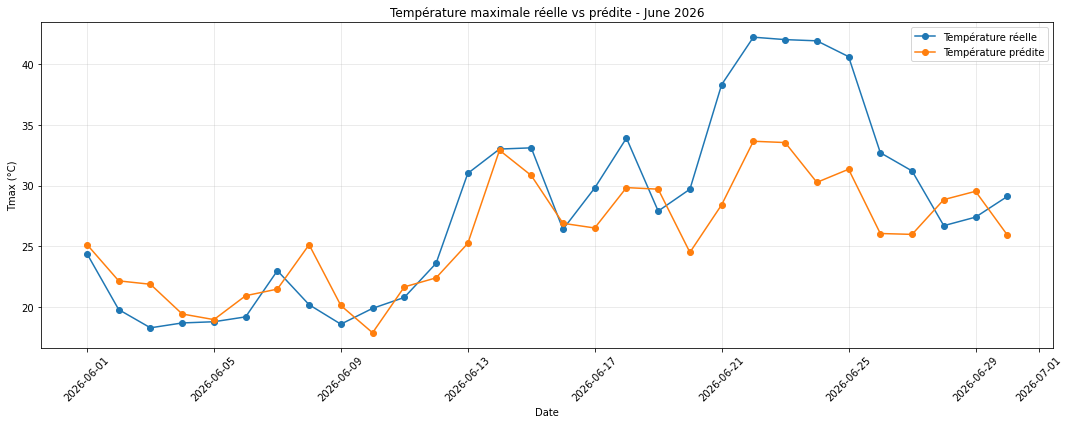

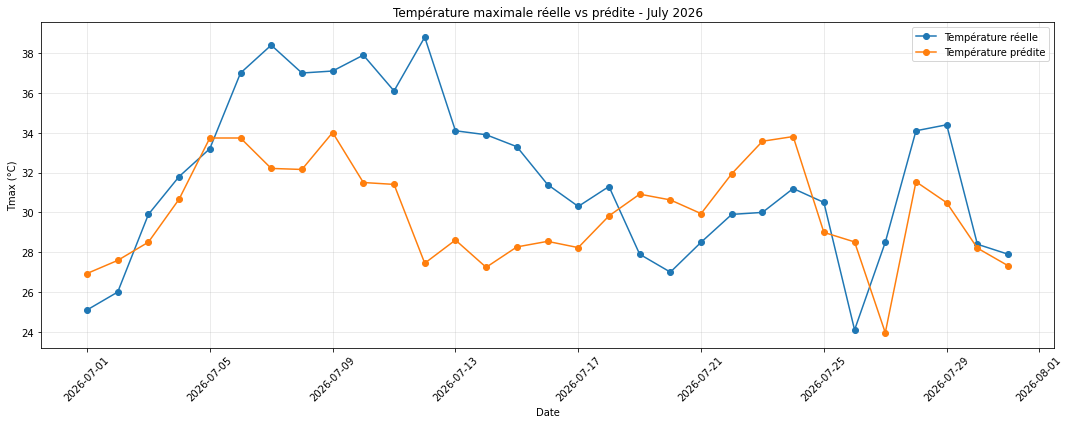

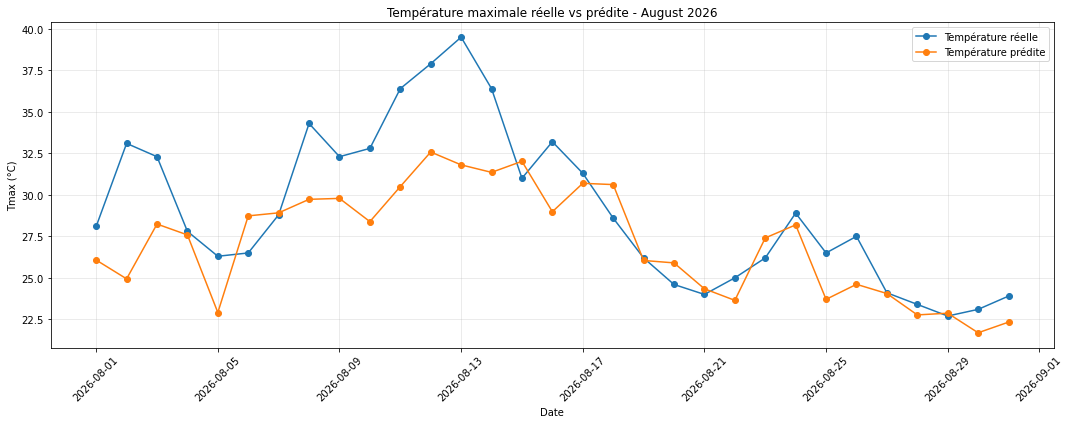

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import os


# On regroupe tout dans un DataFrame pratique
results = pd.DataFrame({
    "date": target_dates_test.values,
    "real": y_test.values,
    "pred": predictions_hgb,
    "persistence": X_test["temperature_max"].values,
})

# Colonnes utiles
results["year"] = results["date"].dt.year
results["month"] = results["date"].dt.month

os.makedirs("plots_hgb", exist_ok=True)

for (year, month), group in results.groupby(["year", "month"]):

    # Nombre de jours théorique dans ce mois
    expected_days = calendar.monthrange(year, month)[1]

    # On vérifie combien de dates différentes on a réellement
    actual_days = group["date"].dt.date.nunique()

    # Si le mois n'est pas complet, on l'ignore
    if actual_days != expected_days:
        continue

    # Tri par date, par sécurité
    group = group.sort_values("date")

    plt.figure(figsize=(15, 6))

    plt.plot(
        group["date"],
        group["real"],
        marker="o",
        label="Température réelle"
    )

    plt.plot(
        group["date"],
        group["pred"],
        marker="o",
        label="Température prédite"
    )
    
    

    plt.xlabel("Date")
    plt.ylabel("Tmax (°C)")

    month_name = calendar.month_name[month]

    plt.title(
        f"Température maximale réelle vs prédite "
        f"- {month_name} {year}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    filename = f"plots_hgb/{year}_{month:02d}.png"

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()